In [13]:
import pandas as pd
import sklearn
from pathlib import Path

current_dir = Path.cwd()
candidate_paths = [
    current_dir / "data" / "processed" / "reviews_cleaned.csv",
    current_dir.parent / "data" / "processed" / "reviews_cleaned.csv",
    Path("A:/DS-Review-AI/data/processed/reviews_cleaned.csv"),
]

csv_path = None
for path in candidate_paths:
    if path.exists():
        csv_path = path
        break

if csv_path is None:
    raise FileNotFoundError("Could not locate reviews_cleaned.csv")

df = pd.read_csv(csv_path)
print(f"Loaded {len(df):,} rows from {csv_path}")

Loaded 393,890 rows from a:\DS-Review-AI\data\processed\reviews_cleaned.csv


In [14]:
binary_df = df[df['sentiment_label'] != 'neutral'].copy()
print(binary_df['sentiment_label'].value_counts())
print(binary_df['sentiment_label'].value_counts(normalize=True) * 100)

sentiment_label
positive    307019
negative     57103
Name: count, dtype: int64
sentiment_label
positive    84.317619
negative    15.682381
Name: proportion, dtype: float64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    binary_df['cleaned_text'], binary_df['sentiment_label'],
    test_size=0.2, stratify=binary_df['sentiment_label'], random_state=42
)
print(f"Train: {len(X_train):,}  Test: {len(X_test):,} (test set locked until final evaluation)")

Train: 291,297  Test: 72,825 (test set locked until final evaluation)


In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Fix: fill any NaN values before vectorizing
X_train = X_train.fillna("")
X_test = X_test.fillna("")

tfidf_vec = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=5)
X_train_tfidf = tfidf_vec.fit_transform(X_train)   # fit ONLY on train — never on test
X_test_tfidf = tfidf_vec.transform(X_test)         # transform test using train's vocabulary

print("Vocabulary size:", len(tfidf_vec.vocabulary_))
print("Train matrix shape:", X_train_tfidf.shape)

Vocabulary size: 20000
Train matrix shape: (291297, 20000)


In [17]:
print("NaN count in cleaned_text:", binary_df['cleaned_text'].isna().sum())
print("Empty string count in cleaned_text:", (binary_df['cleaned_text'] == "").sum())

NaN count in cleaned_text: 2
Empty string count in cleaned_text: 0


In [18]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, f1_score, accuracy_score
import pandas as pd

models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression (default)": LogisticRegression(max_iter=1000, random_state=42),
    "Logistic Regression (balanced)": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Linear SVM (default)": LinearSVC(random_state=42),
    "Linear SVM (balanced)": LinearSVC(class_weight="balanced", random_state=42),
}

results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    report = classification_report(y_test, y_pred, output_dict=True)  # compute ONCE

    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Macro F1": round(f1_score(y_test, y_pred, average="macro"), 4),
        "Neg Precision": round(report['negative']['precision'], 4),
        "Neg Recall": round(report['negative']['recall'], 4),
        "Neg F1": round(report['negative']['f1-score'], 4),
    })

comparison_df = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
print(comparison_df.to_string(index=False))
comparison_df.to_csv('../reports/model_comparison.csv', index=False)

a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
a:\DS-Review-AI\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


                         Model  Accuracy  Macro F1  Neg Precision  Neg Recall  Neg F1
          Linear SVM (default)    0.9542    0.9109         0.8793      0.8202  0.8487
 Logistic Regression (default)    0.9521    0.9040         0.9013      0.7797  0.8361
         Linear SVM (balanced)    0.9407    0.8960         0.7593      0.9102  0.8279
Logistic Regression (balanced)    0.9387    0.8943         0.7455      0.9253  0.8257
                   Naive Bayes    0.9211    0.8210         0.9089      0.5523  0.6871
             Majority Baseline    0.8432    0.4575         0.0000      0.0000  0.0000


In [19]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None detected")

CUDA available: True
GPU: NVIDIA GeForce RTX 3060 Ti


In [20]:
import torch
print(torch.__version__)

2.14.0+cu126


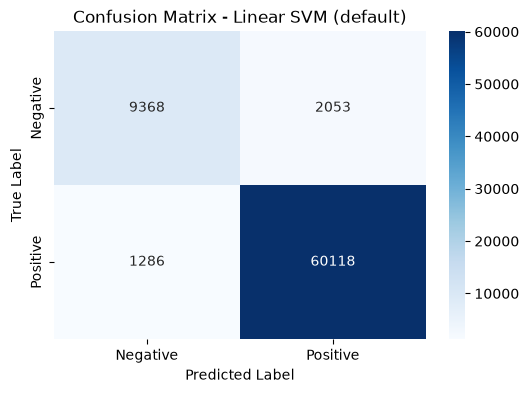

Total Test Samples: 72825
False Positives: 2053 (2.82% of test set)
False Negatives: 1286 (1.77% of test set)

--- SAMPLE FALSE POSITIVES (True: Negative | Pred: Positive) ---
[365 chars] mild not medium ordered maxwell house morning blend tassimo medium larger cup size oz compare gevalia morning roast described medium strength maxwell house arrived labeled mild cof...

[212 chars] liquid not cream product set automatically ship every two months received several shipments creamy however last shipment liquid form mix coconut oil products hair like creamy formu...

[1059 chars] tastes great goes bad beware not diagnosed celiac disease wheat allergy means reaction starts immediately wheat hits stomach diet still celiac diet anyways also allergic eggs lacto...

[379 chars] strawberry tea tea best ever originally bought tea london struggled find found amazon subscription year problem last shipments strawberry sensation not original strawberry good pre...

[231 chars] great nuts ridiculous p

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Explicitly select winning baseline model
best_model = models["Linear SVM (default)"]  # Winner: macro-F1 = 0.9109 in Day 18-19 benchmarking
y_pred_best = best_model.predict(X_test_tfidf)

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best, labels=["negative", "positive"])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=["Negative", "Positive"], 
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Linear SVM (default)")
plt.show()

# 3. Construct Error Analysis DataFrame
test_df = pd.DataFrame({
    "text": X_test,
    "true_label": y_test,
    "pred_label": y_pred_best
})

test_df['correct'] = test_df['true_label'] == test_df['pred_label']
test_df['length'] = test_df['text'].fillna('').str.len()

fps = test_df[(test_df['true_label'] == 'negative') & (test_df['pred_label'] == 'positive')]
fns = test_df[(test_df['true_label'] == 'positive') & (test_df['pred_label'] == 'negative')]

print(f"Total Test Samples: {len(test_df)}")
print(f"False Positives: {len(fps)} ({len(fps)/len(test_df)*100:.2f}% of test set)")
print(f"False Negatives: {len(fns)} ({len(fns)/len(test_df)*100:.2f}% of test set)")

# 4. Neutral Unbiased Headers with Expanded Sample Size (10 examples each)
print("\n--- SAMPLE FALSE POSITIVES (True: Negative | Pred: Positive) ---")
for idx, row in fps.sample(10, random_state=42).iterrows():
    print(f"[{row['length']} chars] {row['text'][:180]}...\n")

print("--- SAMPLE FALSE NEGATIVES (True: Positive | Pred: Negative) ---")
for idx, row in fns.sample(10, random_state=42).iterrows():
    print(f"[{row['length']} chars] {row['text'][:180]}...\n")

# 5. Quantitative Diagnostic: Compare character length stats
print("--- Text Length Summary (Correct vs Misclassified) ---")
print(test_df.groupby('correct')['length'].agg(['count', 'mean', 'median', 'std']).round(2))

In [22]:
import torch
from transformers import pipeline
from sklearn.metrics import classification_report
from tqdm.auto import tqdm

# 1. Initialize Pipeline on GPU
sentiment_pipe = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

# 2. Pass standard Python list of strings
test_texts = X_test.fillna("").tolist()

# 3. Run Inference directly on list
bert_results = []
for out in tqdm(sentiment_pipe(test_texts), total=len(test_texts), desc="DistilBERT Inference"):
    bert_results.append(out)

# 4. Map SST-2 Outputs (POSITIVE/NEGATIVE) to Target Labels
bert_preds = ['positive' if r['label'] == 'POSITIVE' else 'negative' for r in bert_results]

# 5. Evaluate Performance
print("\n=== DistilBERT (Zero-Shot SST-2, GPU) — Held-Out Test Set ===")
print(classification_report(y_test, bert_preds, digits=4))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBERT Inference:   0%|          | 0/72825 [00:00<?, ?it/s]


=== DistilBERT (Zero-Shot SST-2, GPU) — Held-Out Test Set ===
              precision    recall  f1-score   support

    negative     0.3214    0.9471    0.4800     11421
    positive     0.9846    0.6281    0.7670     61404

    accuracy                         0.6782     72825
   macro avg     0.6530    0.7876    0.6235     72825
weighted avg     0.8806    0.6782    0.7220     72825



In [23]:
import pandas as pd
from sklearn.metrics import classification_report

# Pull classification metrics
svm_rep = classification_report(y_test, y_pred_best, output_dict=True)
bert_rep = classification_report(y_test, bert_preds, output_dict=True)

comparison_df = pd.DataFrame([
    {
        "Model": "Linear SVM (TF-IDF)",
        "Type": "Supervised (Domain Trained)",
        "Accuracy": round(svm_rep['accuracy'], 4),
        "Macro F1": round(svm_rep['macro avg']['f1-score'], 4),
        "Pos F1": round(svm_rep['positive']['f1-score'], 4),
        "Neg F1": round(svm_rep['negative']['f1-score'], 4),
        "Inference Speed": "Fast (~seconds)"
    },
    {
        "Model": "DistilBERT (SST-2)",
        "Type": "Zero-Shot (Pre-trained)",
        "Accuracy": round(bert_rep['accuracy'], 4),
        "Macro F1": round(bert_rep['macro avg']['f1-score'], 4),
        "Pos F1": round(bert_rep['positive']['f1-score'], 4),
        "Neg F1": round(bert_rep['negative']['f1-score'], 4),
        "Inference Speed": "Moderate (~minutes on GPU)"
    }
])

print("=== WEEK 3 BASELINE VS TRANSFORMER COMPARISON ===")
display(comparison_df)

=== WEEK 3 BASELINE VS TRANSFORMER COMPARISON ===


,Model,Type,Accuracy,Macro F1,Pos F1,Neg F1,Inference Speed
0,Linear SVM (TF-IDF),Supervised (Domain Trained),0.9542,0.9109,0.973,0.8487,Fast (~seconds)
1,DistilBERT (SST-2),Zero-Shot (Pre-trained),0.6782,0.6235,0.767,0.4800,Moderate (~minutes on GPU)


In [24]:
import torch
from transformers import pipeline
from sklearn.metrics import classification_report
from tqdm.auto import tqdm

# 1. Initialize Pipeline
nlptown_pipe = pipeline(
    "sentiment-analysis",
    model="nlptown/bert-base-multilingual-uncased-sentiment",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

# 2. Run Inference
nlptown_results = []
for out in tqdm(nlptown_pipe(test_texts), total=len(test_texts), desc="NLP Town BERT Inference"):
    nlptown_results.append(out)

# 3. Map Star Outputs ('1 star'..'5 stars') to Target Labels
def map_star_to_sentiment(label):
    star_num = int(label.split()[0])
    return 'positive' if star_num >= 4 else 'negative'

nlptown_preds = [map_star_to_sentiment(r['label']) for r in nlptown_results]

# 4. Evaluate Performance
print("\n=== NLP Town BERT (Amazon/Yelp Product Trained) — Held-Out Test Set ===")
print(classification_report(y_test, nlptown_preds, digits=4))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

NLP Town BERT Inference:   0%|          | 0/72825 [00:00<?, ?it/s]


=== NLP Town BERT (Amazon/Yelp Product Trained) — Held-Out Test Set ===
              precision    recall  f1-score   support

    negative     0.4151    0.9683    0.5811     11421
    positive     0.9922    0.7462    0.8518     61404

    accuracy                         0.7811     72825
   macro avg     0.7036    0.8573    0.7164     72825
weighted avg     0.9017    0.7811    0.8093     72825



In [25]:
# 1. Initialize Pipeline
roberta_pipe = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-roberta-base-sentiment-latest",
    device=0 if torch.cuda.is_available() else -1,
    batch_size=64,
    truncation=True,
    max_length=512
)

# 2. Run Inference
roberta_results = []
for out in tqdm(roberta_pipe(test_texts), total=len(test_texts), desc="RoBERTa Inference"):
    roberta_results.append(out)

# 3. Map Outputs to Target Labels
# Note: If neutral is predicted on a binary test set, map it to 'negative'
roberta_preds = [
    r['label'] if r['label'] in ['positive', 'negative'] else 'negative' 
    for r in roberta_results
]

# 4. Evaluate Performance
print("\n=== RoBERTa Latest — Held-Out Test Set ===")
print(classification_report(y_test, roberta_preds, digits=4))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RoBERTa Inference:   0%|          | 0/72825 [00:00<?, ?it/s]


=== RoBERTa Latest — Held-Out Test Set ===
              precision    recall  f1-score   support

    negative     0.5300    0.9155    0.6714     11421
    positive     0.9818    0.8490    0.9106     61404

    accuracy                         0.8594     72825
   macro avg     0.7559    0.8823    0.7910     72825
weighted avg     0.9110    0.8594    0.8731     72825



In [26]:
import nltk
nltk.download('vader_lexicon')
from nltk.sentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def vader_predict(text):
    score = analyzer.polarity_scores(str(text))['compound']
    return 'positive' if score >= 0 else 'negative'

vader_preds = X_test.fillna("").apply(vader_predict)

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\Ishaan\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


In [27]:
def vader_predict(text):
    score = analyzer.polarity_scores(str(text))['compound']
    return 'positive' if score >= 0 else 'negative'

# On cleaned text (what you just ran)
vader_preds_cleaned = X_test.fillna("").apply(vader_predict)

# On raw/full text — fairer test of VADER's actual design intent
raw_test_text = df.loc[X_test.index, 'full_text']  # or 'Text' if full_text isn't available
vader_preds_raw = raw_test_text.fillna("").apply(vader_predict)

In [28]:
import pandas as pd
from sklearn.metrics import classification_report

model_predictions = {
    "Linear SVM (TF-IDF)": y_pred_best,
    "DistilBERT (SST-2, zero-shot)": bert_preds,
    "NLP Town BERT (zero-shot)": nlptown_preds,
    "RoBERTa (Twitter, zero-shot)": roberta_preds,
    "VADER (lexicon)": vader_preds,
    # "DistilBERT (fine-tuned)": finetuned_preds,   # add once you have it
}

rows = []
for name, preds in model_predictions.items():
    rep = classification_report(y_test, preds, output_dict=True)
    rows.append({
        "Model": name,
        "Accuracy": round(rep['accuracy'], 4),
        "Macro F1": round(rep['macro avg']['f1-score'], 4),
        "Negative F1": round(rep['negative']['f1-score'], 4),
        "Positive F1": round(rep['positive']['f1-score'], 4),
    })

final_comparison = pd.DataFrame(rows).sort_values("Macro F1", ascending=False)
print(final_comparison.to_string(index=False))
final_comparison.to_csv('../reports/final_model_comparison.csv', index=False)

                        Model  Accuracy  Macro F1  Negative F1  Positive F1
          Linear SVM (TF-IDF)    0.9542    0.9109       0.8487       0.9730
 RoBERTa (Twitter, zero-shot)    0.8594    0.7910       0.6714       0.9106
              VADER (lexicon)    0.8851    0.7413       0.5484       0.9342
    NLP Town BERT (zero-shot)    0.7811    0.7164       0.5811       0.8518
DistilBERT (SST-2, zero-shot)    0.6782    0.6235       0.4800       0.7670


In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

X_train_full = X_train.fillna("")

pipe = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1,3), min_df=5)),  # Keep winning params fixed
    ('clf', LinearSVC(max_iter=2000, random_state=42))
])

# Test variations around your best config
param_grid = {
    'tfidf__max_features': [40000, 50000],        # Test if more vocab helps
    'clf__C': [0.5, 1.0, 2.0],                    # Test regularization strength
}

# Total: 2 × 3 = 6 combinations (manageable!)
cv_strategy = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)

search = GridSearchCV(
    pipe, 
    param_grid=param_grid,
    cv=cv_strategy, 
    scoring='f1_macro', 
    n_jobs=2,              # Memory-safe for 16GB RAM
    verbose=2
)

start = time.time()
search.fit(X_train_full, y_train)
elapsed = (time.time() - start) / 60

print(f"\nSearch took {elapsed:.1f} minutes")
print(f"Best parameters: {search.best_params_}")
print(f"Best CV macro-F1: {search.best_score_:.4f}")
print(f"Previous best: 0.9087")
print(f"Improvement: {(search.best_score_ - 0.9087)*100:+.2f} percentage points")


Fitting 2 folds for each of 6 candidates, totalling 12 fits

Search took 7.1 minutes
Best parameters: {'clf__C': 0.5, 'tfidf__max_features': 40000}
Best CV macro-F1: 0.9113
Previous best: 0.9087
Improvement: +0.26 percentage points


In [37]:
from sklearn.metrics import classification_report, f1_score

best_model = search.best_estimator_  # already refit on X_train_full automatically
y_pred_tuned = best_model.predict(X_test.fillna(""))

tuned_f1 = f1_score(y_test, y_pred_tuned, average='macro')

print("=== TUNED MODEL — Held-Out Test Set ===")
print(classification_report(y_test, y_pred_tuned, target_names=['Negative', 'Positive'], digits=4))
print(f"\nOriginal (untuned) test macro-F1: 0.9109")
print(f"Tuned test macro-F1: {tuned_f1:.4f}")
print(f"Difference: {(tuned_f1 - 0.9109)*100:+.2f} percentage points")

=== TUNED MODEL — Held-Out Test Set ===
              precision    recall  f1-score   support

    Negative     0.8926    0.8186    0.8540     11421
    Positive     0.9668    0.9817    0.9742     61404

    accuracy                         0.9561     72825
   macro avg     0.9297    0.9001    0.9141     72825
weighted avg     0.9551    0.9561    0.9553     72825


Original (untuned) test macro-F1: 0.9109
Tuned test macro-F1: 0.9141
Difference: +0.32 percentage points


In [38]:
import joblib
joblib.dump(best_model, '../models/sentiment_model_final.joblib')
print("Final tuned pipeline saved.")

Final tuned pipeline saved.


In [39]:
import sys; print(sys.executable)

a:\DS-Review-AI\.venv\Scripts\python.exe
